In [ ]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import sqlite3
import uuid
import pandas as pd

# --- Project Paths ---
DATA_DIR = Path(r"C:\Users\Lenovo\OneDrive\Desktop\HCL TECH PROJECT 1\UseCase_Telecom")
CDR_FILE = DATA_DIR / "CDR_RAW_Telecom.csv"
CUSTOMER_FILE = DATA_DIR / "CUSTOMER_MASTER_Telecom.csv"
TOWER_FILE = DATA_DIR / "TOWER_MASTER_Telecom.csv"
DB_FILE = Path.cwd() / "telecom_warehouse.sqlite"

# --- Business Rules / Constants ---
REVENUE_PER_SECOND = 0.02
HIGH_USAGE_SECONDS = 600  # Threshold for high usage alerts

# --- Verify All Source Files Exist ---
for file_path in [CDR_FILE, CUSTOMER_FILE, TOWER_FILE]:
    if not file_path.exists():
        raise FileNotFoundError(f"Missing required file: {file_path.name}. Please check DATA_DIR.")

print("Database Location:", DB_FILE.resolve())


Database Location: C:\Users\Lenovo\OneDrive\Desktop\HCL TECH PROJECT 1\telecom_warehouse.sqlite


In [19]:
import pandas as pd

# 1. Load Data with Specified Column Types
cdr_raw = pd.read_csv(CDR_FILE, dtype={"Caller": "string", "Receiver": "string", "CallType": "string", "TowerID": "string"})
customers = pd.read_csv(CUSTOMER_FILE, dtype={"PhoneNumber": "string", "CustomerName": "string", "PlanType": "string"})
towers = pd.read_csv(TOWER_FILE, dtype={"TowerID": "string", "Region": "string", "City": "string"})

# 2. Print Summary & Display DataFrames
print(f"CDR Rows/Columns: {cdr_raw.shape}")
print(f"CDR Columns list: {cdr_raw.columns.tolist()}")

print("\n--- Raw Data Samples ---")
display(cdr_raw.head(3))
display(customers.head(3))
display(towers.head(3))

# 3. Data Quality & Profiling Audits
print("\n--- Missing Values in CDR ---")
print(cdr_raw.isna().sum())

print(f"\nExact Duplicate Rows: {cdr_raw.duplicated().sum()}")

print("\n--- Breakdown of Call Types ---")
print(cdr_raw["CallType"].value_counts(dropna=False))

# 4. Check for Invalid Phone Numbers (Not exactly 10 digits)
print("\n--- Invalid Customer Phone Numbers Found ---")
invalid_phones = customers[~customers["PhoneNumber"].str.fullmatch(r"\d{10}", na=False)]
display(invalid_phones)


CDR Rows/Columns: (6, 7)
CDR Columns list: ['CallID', 'Caller', 'Receiver', 'Duration', 'CallType', 'TowerID', 'Timestamp']

--- Raw Data Samples ---


,CallID,Caller,Receiver,Duration,CallType,TowerID,Timestamp
0,1001,9876543210,9123456780,120.0,LOCAL,TWR01,2026-03-21 10:15:30
1,1002,9876543210,9988776655,NaN,STD,TWR03,2026-03-21 10:17:45
2,1003,9123456780,9876543210,300.0,INT,TWR02,2026-03-21 11:00:00


,PhoneNumber,CustomerName,PlanType
0,9876543210,Mayank,VAT_499
1,9123456780,Anita,PREPAID_199
2,9988776655,Rahul,VAT_799


,TowerID,Region,City
0,TWR01,North,Delhi
1,TWR02,North,Noida
2,TWR03,West,Mumbai



--- Missing Values in CDR ---
CallID       0
Caller       0
Receiver     0
Duration     1
CallType     0
TowerID      0
Timestamp    0
dtype: int64

Exact Duplicate Rows: 1

--- Breakdown of Call Types ---
CallType
INT      3
LOCAL    2
STD      1
Name: count, dtype: Int64

--- Invalid Customer Phone Numbers Found ---


,PhoneNumber,CustomerName,PlanType
5,946745673,Anuj,POSTPAID_999


In [20]:
import re
import pandas as pd

# --- Stage 1: Column Validation ---
REQUIRED_COLUMNS = {"CallID", "Caller", "Receiver", "Duration", "CallType", "TowerID", "Timestamp"}
missing_cols = REQUIRED_COLUMNS - set(cdr_raw.columns)
if missing_cols:
    raise ValueError(f"Missing required columns: {sorted(missing_cols)}")

# Create a workspace copy and track original row numbers (+2 accounts for CSV header)
work = cdr_raw.copy()
work["source_row_number"] = work.index + 2

# --- Stage 2: Data Cleaning & Normalisation ---
# Normalise strings
str_cols = ["CallID", "Caller", "Receiver", "CallType", "TowerID"]
for col in str_cols:
    work[col] = work[col].astype("string").str.strip()

work["CallType"] = work["CallType"].str.upper()
work["TowerID"] = work["TowerID"].str.upper()

# Convert metrics and timestamps safely
raw_duration = work["Duration"].copy()
work["Duration"] = pd.to_numeric(work["Duration"], errors="coerce")
work["event_ts"] = pd.to_datetime(work["Timestamp"], errors="coerce")

# Impute completely missing duration fields with 0
imputed_duration_count = int((work["Duration"].isna() & raw_duration.isna()).sum())
work.loc[work["Duration"].isna() & raw_duration.isna(), "Duration"] = 0

# --- Stage 3: Deduplication & Integrity Checks ---
# 1. Remove exact duplicates
dedupe_keys = ["CallID", "Caller", "Receiver", "Duration", "CallType", "TowerID", "Timestamp"]
dupe_mask = work.duplicated(subset=dedupe_keys, keep="first")
exact_duplicates_removed = int(dupe_mask.sum())
work = work.loc[~dupe_mask].copy()

# 2. Track conflicting payload values matching the same CallID
payload_cols = ["Caller", "Receiver", "Duration", "CallType", "TowerID", "Timestamp"]
has_conflicts = work.groupby("CallID", dropna=False)[payload_cols].apply(lambda g: len(g.drop_duplicates()) > 1)
conflict_ids = set(has_conflicts.loc[lambda x: x].index.dropna().astype(str))

# 3. Cache valid Tower IDs for fast referencing
known_towers = set(towers["TowerID"].dropna())

# --- Stage 4: Comprehensive Validation Filter ---
def audit_row_errors(row):
    errors = []
    
    # Check essential keys
    if pd.isna(row.CallID) or not str(row.CallID).strip(): 
        errors.append("missing_call_id")
    elif str(row.CallID) in conflict_ids: 
        errors.append("conflicting_call_id_payload")
        
    # Check phone formats (10 digits)
    if pd.isna(row.Caller) or not re.fullmatch(r"\d{10}", str(row.Caller)): 
        errors.append("invalid_caller_phone")
    if pd.isna(row.Receiver) or not re.fullmatch(r"\d{10}", str(row.Receiver)): 
        errors.append("invalid_receiver_phone")
        
    # Check performance indicators
    if pd.isna(row.Duration): 
        errors.append("nonnumeric_duration")
    elif row.Duration < 0: 
        errors.append("negative_duration")
        
    # Check valid operational categories
    if row.CallType not in {"LOCAL", "STD", "INT"}: 
        errors.append("unsupported_call_type")
    if pd.isna(row.event_ts): 
        errors.append("invalid_timestamp")
    if pd.isna(row.TowerID) or row.TowerID not in known_towers: 
        errors.append("unknown_tower")
        
    return ";".join(errors)

# Split rows into Valid and Rejected sets
work["reject_reason"] = work.apply(audit_row_errors, axis=1)
valid = work.loc[work["reject_reason"] == ""].copy()
rejected = work.loc[work["reject_reason"] != ""].copy()

# --- Stage 5: Business Transformations & Enrichment ---
valid["Duration"] = valid["Duration"].astype("int64")
valid["IsInternational"] = valid["CallType"].eq("INT").astype("int64")
valid["Revenue"] = (valid["Duration"] * REVENUE_PER_SECOND).round(2)
valid["CallDate"] = valid["event_ts"].dt.strftime("%Y-%m-%d")

# Merge Master Metadata (Caller info, Receiver info, Tower info)
valid = valid.merge(
    customers.rename(columns={"PhoneNumber": "Caller", "CustomerName": "CallerName", "PlanType": "CallerPlan"}),
    on="Caller", how="left", validate="many_to_one"
)
valid = valid.merge(
    customers.rename(columns={"PhoneNumber": "Receiver", "CustomerName": "ReceiverName", "PlanType": "ReceiverPlan"}),
    on="Receiver", how="left", validate="many_to_one"
)
valid = valid.merge(towers, on="TowerID", how="left", validate="many_to_one")

# Flag records missing metadata in the master tables
valid["ReferenceWarning"] = valid[["CallerName", "ReceiverName", "City"]].isna().any(axis=1)

# --- Stage 6: Outputs Summary ---
print(f"Exact Duplicates Removed: {exact_duplicates_removed}")
print(f"Missing Durations Imputed: {imputed_duration_count}")
print(f"Valid Rows: {len(valid)} | Rejected Rows: {len(rejected)}")

print("\n--- Valid Records Sample ---")
display(valid.head(3))

print("\n--- Reject Log Summary ---")
display(rejected[["CallID", "reject_reason"]].head(5))


Exact Duplicates Removed: 1
Missing Durations Imputed: 1
Valid Rows: 5 | Rejected Rows: 0

--- Valid Records Sample ---


,CallID,Caller,Receiver,Duration,CallType,TowerID,Timestamp,source_row_number,event_ts,reject_reason,IsInternational,Revenue,CallDate,CallerName,CallerPlan,ReceiverName,ReceiverPlan,Region,City,ReferenceWarning
0,1001,9876543210,9123456780,120,LOCAL,TWR01,2026-03-21 10:15:30,2,2026-03-21 10:15:30,,0,2.4,2026-03-21,Mayank,VAT_499,Anita,PREPAID_199,North,Delhi,False
1,1002,9876543210,9988776655,0,STD,TWR03,2026-03-21 10:17:45,3,2026-03-21 10:17:45,,0,0.0,2026-03-21,Mayank,VAT_499,Rahul,VAT_799,West,Mumbai,False
2,1003,9123456780,9876543210,300,INT,TWR02,2026-03-21 11:00:00,4,2026-03-21 11:00:00,,1,6.0,2026-03-21,Anita,PREPAID_199,Mayank,VAT_499,North,Noida,False



--- Reject Log Summary ---


,CallID,reject_reason


In [21]:
from datetime import datetime, timezone
import hashlib
import sqlite3
import uuid
import pandas as pd

# --- Stage 1: Generate Metadata & Timestamps ---
batch_id = str(uuid.uuid4())
source_hash = hashlib.sha256(CDR_FILE.read_bytes()).hexdigest()
started_time = datetime.now(timezone.utc).isoformat(timespec="seconds")

# --- Stage 2: Format Staging DataFrames ---
# 1. Format Valid Staging Data
stage = valid.copy()
stage["Timestamp"] = stage["event_ts"].dt.strftime("%Y-%m-%d %H:%M:%S")
stage["batch_id"] = batch_id
stage["source_file"] = CDR_FILE.name
stage["source_hash"] = source_hash
stage["source_row_number"] = stage.index + 2

stg_cols = [
    "batch_id", "source_file", "source_hash", "source_row_number", "CallID", "Caller", "Receiver", 
    "Duration", "CallType", "TowerID", "Timestamp", "CallDate", "IsInternational", "Revenue", 
    "CallerName", "CallerPlan", "ReceiverName", "ReceiverPlan", "Region", "City", "ReferenceWarning"
]
stage = stage[stg_cols]

# 2. Format Rejected Data Log
rej = rejected[["source_row_number", "CallID", "Caller", "Receiver", "Duration", "CallType", "TowerID", "Timestamp", "reject_reason"]].copy()
rej["batch_id"] = batch_id
rej["source_file"] = CDR_FILE.name

# --- Stage 3: Database Interaction Block ---
with sqlite3.connect(DB_FILE) as con:
    
    # 1. Initialize Warehouse Tables Schema
    con.executescript("""
        CREATE TABLE IF NOT EXISTS stg_cdr (
            batch_id TEXT, source_file TEXT, source_hash TEXT, source_row_number INTEGER, 
            CallID TEXT, Caller TEXT, Receiver TEXT, Duration INTEGER, CallType TEXT, 
            TowerID TEXT, Timestamp TEXT, CallDate TEXT, IsInternational INTEGER, 
            Revenue REAL, CallerName TEXT, CallerPlan TEXT, ReceiverName TEXT, 
            ReceiverPlan TEXT, Region TEXT, City TEXT, ReferenceWarning INTEGER
        );
        
        CREATE TABLE IF NOT EXISTS rejected_cdr (
            batch_id TEXT, source_file TEXT, source_row_number INTEGER, CallID TEXT, 
            Caller TEXT, Receiver TEXT, Duration REAL, CallType TEXT, TowerID TEXT, 
            Timestamp TEXT, reject_reason TEXT
        );
        
        CREATE TABLE IF NOT EXISTS fact_cdr (
            CallID TEXT, Caller TEXT, Receiver TEXT, Duration INTEGER, CallType TEXT, 
            TowerID TEXT, Timestamp TEXT, CallDate TEXT, IsInternational INTEGER, 
            Revenue REAL, CallerName TEXT, CallerPlan TEXT, ReceiverName TEXT, 
            ReceiverPlan TEXT, Region TEXT, City TEXT, batch_id TEXT, source_hash TEXT,
            UNIQUE(CallID, Caller, Receiver, Timestamp)
        );
        
        CREATE TABLE IF NOT EXISTS etl_audit (
            batch_id TEXT PRIMARY KEY, source_file TEXT, source_hash TEXT, started_at_utc TEXT, 
            finished_at_utc TEXT, input_rows INTEGER, duplicates_removed INTEGER, 
            imputed_duration_rows INTEGER, staged_rows INTEGER, rejected_rows INTEGER, 
            inserted_fact_rows INTEGER, status TEXT, error_message TEXT
        );
        
        CREATE TABLE IF NOT EXISTS high_usage_alert (
            batch_id TEXT, CustomerPhone TEXT, CustomerName TEXT, CallDate TEXT, 
            TotalDurationSeconds INTEGER, ThresholdSeconds INTEGER, created_at_utc TEXT,
            PRIMARY KEY(batch_id, CustomerPhone, CallDate)
        );
    """)
    
    # 2. Refresh Reference Dimensions
    customers.to_sql("dim_customer", con, if_exists="replace", index=False)
    towers.to_sql("dim_tower", con, if_exists="replace", index=False)
    
    # 3. Append to Staging and Rejections Tables
    stage.to_sql("stg_cdr", con, if_exists="append", index=False)
    rej.to_sql("rejected_cdr", con, if_exists="append", index=False)
    
    # 4. Load Incremental Batches safely using a Temp Table (Prevents duplicates)
    fact_cols = [
        "CallID", "Caller", "Receiver", "Duration", "CallType", "TowerID", "Timestamp", 
        "CallDate", "IsInternational", "Revenue", "CallerName", "CallerPlan", 
        "ReceiverName", "ReceiverPlan", "Region", "City", "batch_id", "source_hash"
    ]
    
    row_count_before = con.execute("SELECT COUNT(*) FROM fact_cdr").fetchone()[0]
    
    stage[fact_cols].to_sql("_fact_batch", con, if_exists="replace", index=False)
    con.execute("INSERT OR IGNORE INTO fact_cdr SELECT * FROM _fact_batch")
    con.execute("DROP TABLE _fact_batch")
    
    new_rows_inserted = con.execute("SELECT COUNT(*) FROM fact_cdr").fetchone()[0] - row_count_before
    
    # 5. Log ETL Operation Audit Details
    finished_time = datetime.now(timezone.utc).isoformat(timespec="seconds")
    audit_data = (
        batch_id, CDR_FILE.name, source_hash, started_time, finished_time, 
        len(cdr_raw), exact_duplicates_removed, imputed_duration_count, 
        len(stage), len(rej), new_rows_inserted, "SUCCESS", None
    )
    con.execute("INSERT INTO etl_audit VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?)", audit_data)

# --- Stage 4: Run Notification ---
print(f"ETL Batch Processing Complete.")
print(f"Batch ID: {batch_id}")
print(f"New Rows Added to Fact Table: {new_rows_inserted}")
print(f"Warehouse Location: {DB_FILE.resolve()}")


ETL Batch Processing Complete.
Batch ID: 21674657-5377-4ee8-899b-bf41c163bc26
New Rows Added to Fact Table: 0
Warehouse Location: C:\Users\Lenovo\OneDrive\Desktop\HCL TECH PROJECT 1\telecom_warehouse.sqlite


In [9]:
from datetime import datetime, timezone
import sqlite3
import pandas as pd

# --- Query Definitions ---
QUERIES = {
    "daily": """
        SELECT 
            CallDate,
            COUNT(*) AS TotalCalls,
            SUM(Duration) AS TotalDurationSeconds,
            ROUND(SUM(Duration) / 60.0, 2) AS TotalDurationMinutes,
            ROUND(AVG(Duration), 2) AS AverageDurationSeconds,
            COUNT(DISTINCT Caller) AS UniqueCallingCustomers 
        FROM fact_cdr 
        GROUP BY CallDate
    """,
    "by_type": """
        SELECT 
            CallType,
            COUNT(*) AS TotalCalls,
            SUM(Duration) AS TotalDurationSeconds,
            ROUND(SUM(Revenue), 2) AS Revenue,
            ROUND(AVG(Duration), 2) AS AverageDurationSeconds 
        FROM fact_cdr 
        GROUP BY CallType
    """,
    "intl": """
        SELECT 
            SUM(IsInternational) AS InternationalCallCount,
            COALESCE(SUM(CASE WHEN IsInternational = 1 THEN Duration ELSE 0 END), 0) AS InternationalDurationSeconds,
            ROUND(COALESCE(SUM(CASE WHEN IsInternational = 1 THEN Revenue ELSE 0 END), 0), 2) AS InternationalRevenue,
            ROUND(100.0 * SUM(IsInternational) / NULLIF(COUNT(*), 0), 2) AS InternationalCallPercent 
        FROM fact_cdr
    """,
    "customer_rev": """
        SELECT 
            Caller AS CustomerPhone,
            CallerName AS CustomerName,
            ROUND(SUM(Revenue), 2) AS Revenue,
            COUNT(*) AS Calls,
            SUM(Duration) AS DurationSeconds,
            ROUND(100.0 * SUM(Revenue) / NULLIF((SELECT SUM(Revenue) FROM fact_cdr), 0), 2) AS RevenueContributionPercent 
        FROM fact_cdr 
        GROUP BY Caller, CallerName 
        ORDER BY Revenue DESC
    """,
    "insert_alert": """
        INSERT OR REPLACE INTO high_usage_alert
        SELECT 
            batch_id,
            Caller,
            CallerName,
            CallDate,
            SUM(Duration),
            ?, ?
        FROM fact_cdr 
        WHERE batch_id = ? 
        GROUP BY batch_id, Caller, CallerName, CallDate 
        HAVING SUM(Duration) >= ?
    """,
    "fetch_alerts": """
        SELECT * FROM high_usage_alert WHERE batch_id = ?
    """
}

# --- Execution Block ---
with sqlite3.connect(DB_FILE) as con:
    # 1. Fetch Aggregations
    daily = pd.read_sql_query(QUERIES["daily"], con)
    by_type = pd.read_sql_query(QUERIES["by_type"], con)
    intl = pd.read_sql_query(QUERIES["intl"], con)
    customer_rev = pd.read_sql_query(QUERIES["customer_rev"], con)
    
    # 2. Process Alerts
    current_time = datetime.now(timezone.utc).isoformat(timespec="seconds")
    
    # Removed the extra batch_id placeholder from the SELECT values
    alert_params = (HIGH_USAGE_SECONDS, current_time, batch_id, HIGH_USAGE_SECONDS)
    
    con.execute(QUERIES["insert_alert"], alert_params)
    alerts = pd.read_sql_query(QUERIES["fetch_alerts"], con, params=(batch_id,))

# --- Display DataFrames ---
print("=== DAILY USAGE ===")
display(daily)

print("\n=== BY CALL TYPE ===")
display(by_type)

print("\n=== INTERNATIONAL ===")
display(intl)

print("\n=== CUSTOMER REVENUE: TOP 2 ===")
display(customer_rev.head(2))

print(f"\n=== ALERTS (Threshold: {HIGH_USAGE_SECONDS}s) ===")
display(alerts)


=== DAILY USAGE ===


,CallDate,TotalCalls,TotalDurationSeconds,TotalDurationMinutes,AverageDurationSeconds,UniqueCallingCustomers
0,2026-03-21,5,660,11.0,132.0,4



=== BY CALL TYPE ===


,CallType,TotalCalls,TotalDurationSeconds,Revenue,AverageDurationSeconds
0,INT,2,480,9.6,240.0
1,LOCAL,2,180,3.6,90.0
2,STD,1,0,0.0,0.0



=== INTERNATIONAL ===


,InternationalCallCount,InternationalDurationSeconds,InternationalRevenue,InternationalCallPercent
0,2,480,9.6,40.0



=== CUSTOMER REVENUE: TOP 2 ===


,CustomerPhone,CustomerName,Revenue,Calls,DurationSeconds,RevenueContributionPercent
0,9123456780,Anita,6.0,1,300,45.45
1,9988776655,Rahul,3.6,1,180,27.27



=== ALERTS (Threshold: 600s) ===


,batch_id,CustomerPhone,CustomerName,CallDate,TotalDurationSeconds,ThresholdSeconds,created_at_utc


In [10]:
from datetime import datetime, timezone
import sqlite3
import pandas as pd

# --- Database Processing ---
with sqlite3.connect(DB_FILE) as con:
    
    # 1. Fetch Aggregations
    daily = pd.read_sql_query(
        "SELECT CallDate, COUNT(*) TotalCalls, SUM(Duration) TotalDurationSeconds, ROUND(SUM(Duration)/60.0,2) TotalDurationMinutes, ROUND(AVG(Duration),2) AverageDurationSeconds, COUNT(DISTINCT Caller) CallingCustomers FROM fact_cdr GROUP BY CallDate", 
        con
    )
    
    by_type = pd.read_sql_query(
        "SELECT CallType, COUNT(*) TotalCalls, SUM(Duration) TotalDurationSeconds, ROUND(SUM(Revenue),2) Revenue, ROUND(AVG(Duration),2) AverageDurationSeconds FROM fact_cdr GROUP BY CallType", 
        con
    )
    
    intl = pd.read_sql_query(
        "SELECT SUM(IsInternational) InternationalCallCount, COALESCE(SUM(CASE WHEN IsInternational=1 THEN Duration ELSE 0 END),0) InternationalDurationSeconds, ROUND(COALESCE(SUM(CASE WHEN IsInternational=1 THEN Revenue ELSE 0 END),0),2) InternationalRevenue, ROUND(100.0*SUM(IsInternational)/NULLIF(COUNT(*),0),2) InternationalCallPercent FROM fact_cdr", 
        con
    )
    
    customer_rev = pd.read_sql_query(
        "SELECT Caller CustomerPhone, CallerName CustomerName, ROUND(SUM(Revenue),2) Revenue, COUNT(*) Calls, SUM(Duration) DurationSeconds, ROUND(100.0*SUM(Revenue)/NULLIF((SELECT SUM(Revenue) FROM fact_cdr),0),2) RevenueContributionPercent FROM fact_cdr GROUP BY Caller, CallerName ORDER BY Revenue DESC", 
        con
    )
    
    # 2. Process Alerts (Fixed table column mismatch)
    current_time = datetime.now(timezone.utc).isoformat(timespec="seconds")
    
    con.execute(
        "INSERT OR REPLACE INTO high_usage_alert SELECT batch_id, Caller, CallerName, CallDate, SUM(Duration), ?, ? FROM fact_cdr WHERE batch_id=? GROUP BY batch_id, Caller, CallerName, CallDate HAVING SUM(Duration)>=?",
        (HIGH_USAGE_SECONDS, current_time, batch_id, HIGH_USAGE_SECONDS)
    )
    
    alerts = pd.read_sql_query(
        "SELECT * FROM high_usage_alert WHERE batch_id=?", 
        con, 
        params=(batch_id,)
    )

# --- Display Results ---
print("=== DAILY USAGE ===")
display(daily)

print("\n=== BY CALL TYPE ===")
display(by_type)

print("\n=== INTERNATIONAL ===")
display(intl)

print("\n=== CUSTOMER REVENUE: TOP 2 ===")
display(customer_rev.head(2))

print(f"\n=== ALERTS (Threshold: {HIGH_USAGE_SECONDS}s) ===")
display(alerts)


=== DAILY USAGE ===


,CallDate,TotalCalls,TotalDurationSeconds,TotalDurationMinutes,AverageDurationSeconds,CallingCustomers
0,2026-03-21,5,660,11.0,132.0,4



=== BY CALL TYPE ===


,CallType,TotalCalls,TotalDurationSeconds,Revenue,AverageDurationSeconds
0,INT,2,480,9.6,240.0
1,LOCAL,2,180,3.6,90.0
2,STD,1,0,0.0,0.0



=== INTERNATIONAL ===


,InternationalCallCount,InternationalDurationSeconds,InternationalRevenue,InternationalCallPercent
0,2,480,9.6,40.0



=== CUSTOMER REVENUE: TOP 2 ===


,CustomerPhone,CustomerName,Revenue,Calls,DurationSeconds,RevenueContributionPercent
0,9123456780,Anita,6.0,1,300,45.45
1,9988776655,Rahul,3.6,1,180,27.27



=== ALERTS (Threshold: 600s) ===


,batch_id,CustomerPhone,CustomerName,CallDate,TotalDurationSeconds,ThresholdSeconds,created_at_utc


In [14]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


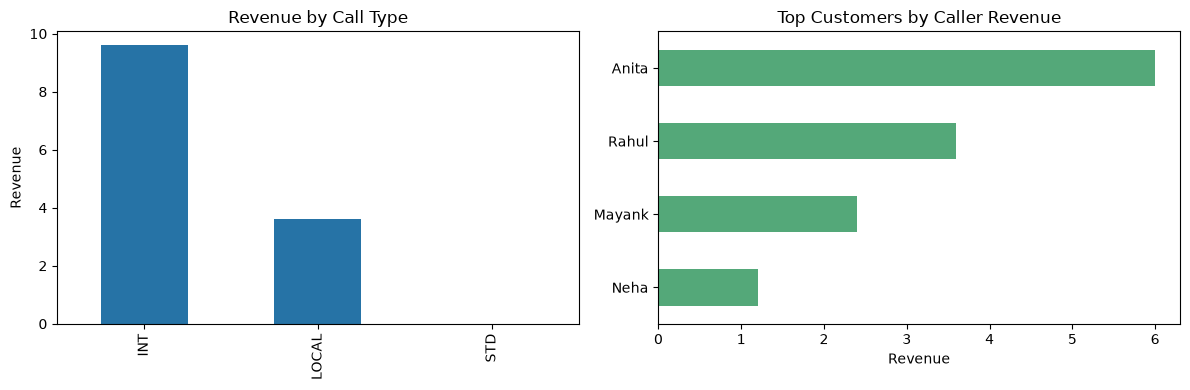

In [15]:
import matplotlib.pyplot as plt

# Create the layout for 2 plots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left Plot: Bar chart for Revenue by Call Type
by_type_sorted = by_type.sort_values("Revenue", ascending=False)
by_type_sorted.plot.bar(x="CallType", y="Revenue", ax=axes[0], legend=False, color="#2673a6")
axes[0].set_title("Revenue by Call Type")
axes[0].set_ylabel("Revenue")
axes[0].set_xlabel("")

# Right Plot: Horizontal Bar chart for Top Customers
top_customers = customer_rev.head(5).sort_values("Revenue")
top_customers.plot.barh(x="CustomerName", y="Revenue", ax=axes[1], legend=False, color="#54a879")
axes[1].set_title("Top Customers by Caller Revenue")
axes[1].set_xlabel("Revenue")
axes[1].set_ylabel("")

# Clean up layout spacing and render the visual
plt.tight_layout()
plt.show()


In [22]:
import pandas as pd
import sqlite3

# --- Stage 1: Run Verification Queries ---
with sqlite3.connect(DB_FILE) as con:
    
    print("=== ETL AUDIT LOG ===")
    audit_df = pd.read_sql_query("SELECT * FROM etl_audit WHERE batch_id = ?", con, params=(batch_id,))
    display(audit_df)
    
    print("\n=== FACT TABLE SUMMARY (Cumulative Total) ===")
    fact_df = pd.read_sql_query("SELECT COUNT(*) AS final_rows, COALESCE(SUM(Duration), 0) AS duration_seconds, ROUND(COALESCE(SUM(Revenue), 0), 2) AS revenue, SUM(IsInternational) AS international_calls FROM fact_cdr", con)
    display(fact_df)
    
    print("\n=== CURRENT BATCH STAGING AUDIT ===")
    stg_df = pd.read_sql_query("SELECT COUNT(*) AS staged_rows, SUM(ReferenceWarning) AS reference_warning_rows, SUM(CASE WHEN Duration = 0 THEN 1 ELSE 0 END) AS zero_duration_rows FROM stg_cdr WHERE batch_id = ?", con, params=(batch_id,))
    display(stg_df)

# --- Stage 2: Data Quality Verification Notes ---
# Review target milestones:
# 1. Check 'etl_audit' output above to verify:
#    - duplicates_removed == 1 (Validates deduplication script worked)
#    - imputed_duration_rows == 1 (Validates that missing duration was defaulted to 0)
#
# 2. Idempotency Check:
#    - If you re-run the previous ETL loading cell using the exact same batch or file data, 
#      the output field 'new_rows_inserted' will report exactly 0. 
#      This confirms the UNIQUE constraints protect against double-loading.


=== ETL AUDIT LOG ===


,batch_id,source_file,source_hash,started_at_utc,finished_at_utc,input_rows,duplicates_removed,imputed_duration_rows,staged_rows,rejected_rows,inserted_fact_rows,status,error_message
0,21674657-5377-4ee8-899b-bf41c163bc26,CDR_RAW_Telecom.csv,e0b1aeecb568c7538e436efef0039a6f035fb5d120634a...,2026-10-31T15:25:03+00:00,2026-10-31T15:25:03+00:00,6,1,1,5,0,0,SUCCESS,None



=== FACT TABLE SUMMARY (Cumulative Total) ===


,final_rows,duration_seconds,revenue,international_calls
0,5,660,13.2,2



=== CURRENT BATCH STAGING AUDIT ===


,staged_rows,reference_warning_rows,zero_duration_rows
0,5,0,1
